[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cauasantoslt/CardioIA/blob/main/Fase4/notebooks/01_preprocessamento_ecg.ipynb)

# FIAP — Inteligência Artificial (PBL · 2º Ano)
## CardioIA: A Nova Era da Cardiologia Inteligente
### Fase 4 (Parte 1) — Pré-processamento e Organização de Imagens Médicas de ECG

* **Aluno:** Cauã Santos — **RM:** 566599
* **Dataset:** *ECG Image Data (MIT-BIH Arrhythmia / Padrão AAMI — 6 Classes)* disponível em `Fase1/assets/images/ECG_Image_data/`
* **Objetivo:** Implementar e documentar um pipeline completo e clinicamente seguro de pré-processamento de imagens de Eletrocardiograma (ECG), incluindo auditoria de integridade, **detecção e remoção de viés cromático**, recorte da Região de Interesse (ROI), redimensionamento, normalização, divisão estratificada (Treino, Validação e Teste) e *Data Augmentation* válido para sinais cardiológicos.
            

---
## 1. Configuração do Ambiente (Compatível com Google Colab e Execução Local)

Caso o notebook seja aberto diretamente no **Google Colab**, a célula abaixo clona automaticamente o repositório oficial do projeto `CardioIA` para disponibilizar o dataset de ECG e os módulos reutilizáveis em `Fase4/src/`.
            

In [1]:
import os
import sys
import json
from pathlib import Path

# Detecta se está no Google Colab sem o repositório clonado
if "google.colab" in sys.modules and not Path("/content/CardioIA").exists():
    os.system("git clone https://github.com/cauasantoslt/CardioIA.git /content/CardioIA")

# Localiza raiz do projeto CardioIA
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent, Path("/content/CardioIA")]
PROJECT_ROOT = next((p for p in candidates if (p / "Fase1" / "assets" / "images" / "ECG_Image_data").exists()), None)
assert PROJECT_ROOT is not None, "Repositório CardioIA não encontrado."

SRC_DIR = PROJECT_ROOT / "Fase4" / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from preprocessamento import (
    CLASSES,
    CLASS_INFO,
    STD_ROI_BOX,
    auditar_e_organizar_dataset,
    compor_sobre_branco,
    extrair_mascara_traco_invariante_cor,
    preprocessar_imagem_ecg,
    recortar_roi_ecg,
)
from modelos import augmentar_ecg_clinico

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print(f"Projeto localizado em: {PROJECT_ROOT}")
print(f"Classes AAMI configuradas ({len(CLASSES)}): {CLASSES}")
            

Projeto localizado em: C:\Users\Pichau\Downloads\FIAP\2ANO\TRABALHOS\CardioIA
Classes AAMI configuradas (6): ['F', 'M', 'N', 'Q', 'S', 'V']


---
## 2. Auditoria do Dataset Bruto e Descoberta Crítica de Viés Cromático

Antes de aplicar qualquer transformação, auditamos as **420 imagens** do dataset (`train/` + `test/`):
1. **Resolução e Canais:** Todas as imagens estão em `432×288` píxeis no formato `RGBA` (4 canais com canal alfa de transparência).
2. **Integridade / Duplicatas:** Verificação por hash criptográfico `MD5` para garantir **zero imagens duplicadas** e **zero vazamento** entre Treino, Validação e Teste.
3. **Achado Crítico (Shortcut Bias):** Cada uma das 6 classes AAMI foi originalmente plotada com uma **cor fixa exclusiva** (`F`=Azul, `M`=Preto, `N`=Ciano, `Q`=Amarelo, `S`=Vermelho, `V`=Verde). Mesmo uma conversão ingênua para escala de cinza (`convert('L')`) preserva **luminâncias distintas por classe** (0 a 169), permitindo que uma CNN "trapaceie" decorando a cor em vez da morfologia do complexo QRS/ST!
            

In [2]:
processed_dir = PROJECT_ROOT / "Fase4" / "data" / "processed"
df_manifest, summary = auditar_e_organizar_dataset(val_ratio=0.20, seed=42, save_dir=processed_dir)

print("=== RESUMO DA AUDITORIA DO DATASET ===")
print(f"Total de imagens:       {summary['total_images']}")
print(f"Resolução/Formato raw:  {summary['raw_resolution']} ({summary['raw_mode']})")
print(f"Hashes MD5 únicos:      {summary['integrity']['unique_hashes']} (duplicatas = {summary['integrity']['duplicates_total']})")
print(f"Sobreposição Train/Val: {summary['integrity']['overlap_train_val']} | Train/Test: {summary['integrity']['overlap_train_test']}")
print(f"Partição final:         Train={summary['splits']['train']} | Val={summary['splits']['val']} | Test={summary['splits']['test']}")

audit_rows = []
for cls in CLASSES:
    cinfo = summary["chromatic_bias_audit"][cls]
    audit_rows.append({
        "Classe": cls,
        "Significado Clínico": CLASS_INFO[cls]["name_pt"],
        "Risco": CLASS_INFO[cls]["risk_level"],
        "Amostras": cinfo["count_total"],
        "Cor Original": CLASS_INFO[cls]["cor_original_dataset"],
        "RGB Mediano": str(cinfo["median_rgb"]),
        "Luminância Grayscale": cinfo["median_luminance"],
    })
df_audit = pd.DataFrame(audit_rows)
print("\nTabela de Auditoria Cromática por Classe:")
print(df_audit.to_string(index=False))
            

=== RESUMO DA AUDITORIA DO DATASET ===
Total de imagens:       420
Resolução/Formato raw:  432x288 (RGBA)
Hashes MD5 únicos:      420 (duplicatas = 0)
Sobreposição Train/Val: 0 | Train/Test: 0
Partição final:         Train=240 | Val=60 | Test=120

Tabela de Auditoria Cromática por Classe:
Classe                         Significado Clínico    Risco  Amostras Cor Original   RGB Mediano  Luminância Grayscale
     F              Batimento de Fusão Ventricular     ALTO        70         Azul   [0, 0, 255]                  29.1
     M  Infarto do Miocárdio / Alteração Isquêmica  CRITICO        70        Preto     [0, 0, 0]                   0.0
     N                    Batimento Sinusal Normal    BAIXO        70        Ciano [0, 191, 191]                 133.9
     Q Batimento de Marca-passo ou Inclassificável MODERADO        70      Amarelo [191, 191, 0]                 169.2
     S              Extrassístole Supraventricular MODERADO        70     Vermelho   [255, 0, 0]                  7

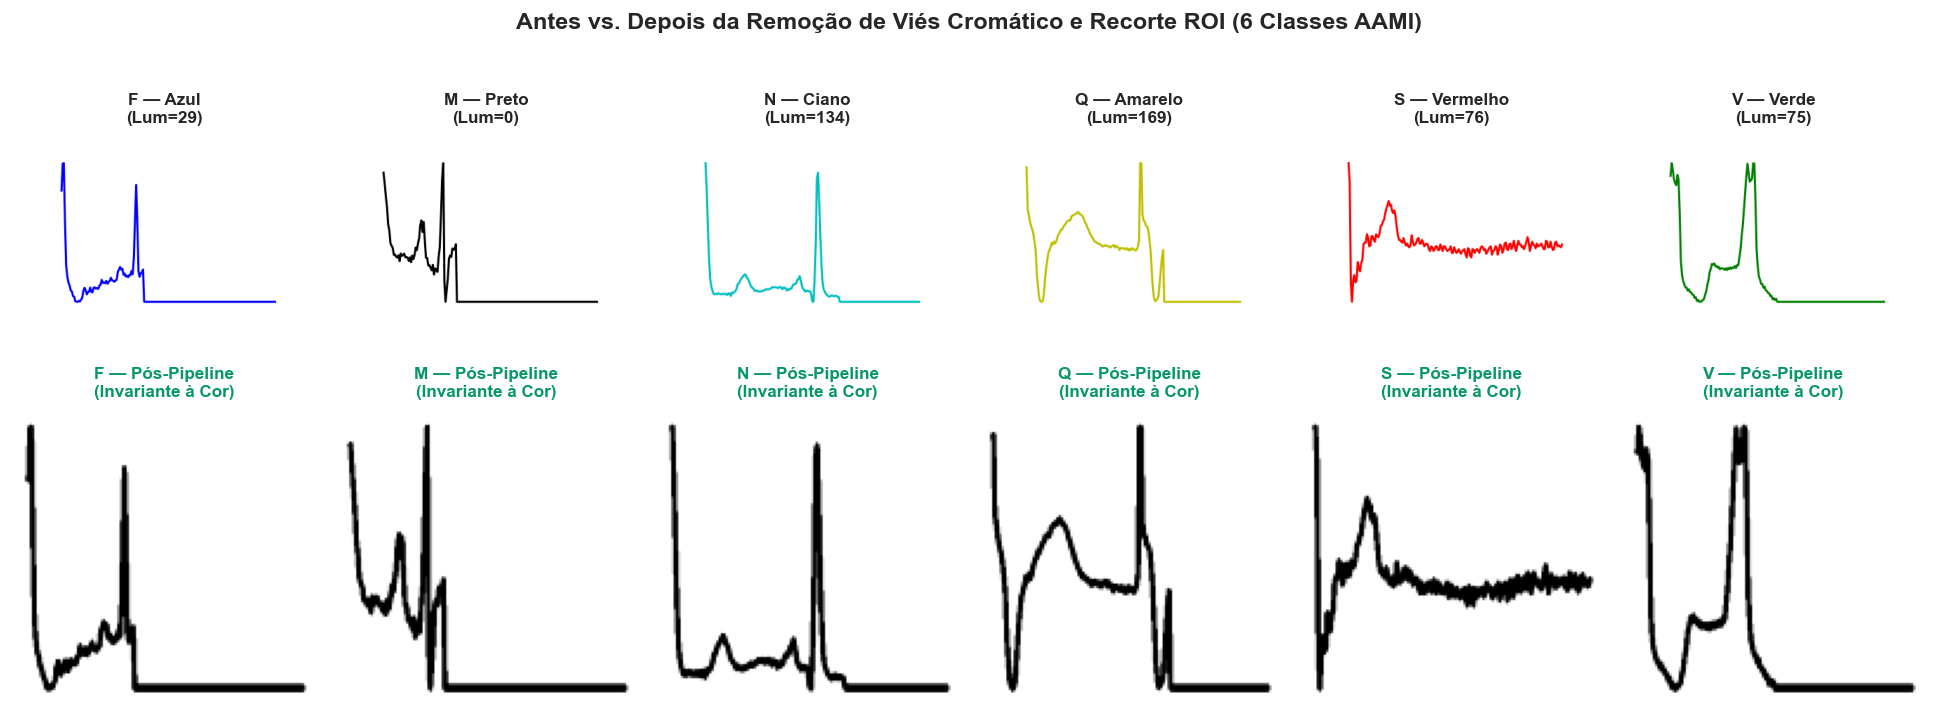

In [3]:
# Visualização das 6 classes originais e evidência do viés de cor/luminância
fig, axes = plt.subplots(2, 6, figsize=(15, 5.8))
for i, cls in enumerate(CLASSES):
    fpath = df_manifest[(df_manifest["label"] == cls) & (df_manifest["split"] == "train")].iloc[0]["abs_path"]
    raw_rgb = compor_sobre_branco(Image.open(fpath))
    bin_arr = preprocessar_imagem_ecg(fpath, target_size=(128, 128), modo="binarizado", para_transfer_learning=True)

    axes[0, i].imshow(raw_rgb)
    lum = summary["chromatic_bias_audit"][cls]["median_luminance"]
    axes[0, i].set_title(f"{cls} — {CLASS_INFO[cls]['cor_original_dataset']}\n(Lum={lum:.0f})", fontsize=9.5, fontweight="bold")
    axes[0, i].axis("off")

    axes[1, i].imshow(bin_arr[:, :, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_title(f"{cls} — Pós-Pipeline\n(Invariante à Cor)", fontsize=9.5, fontweight="bold", color="#059669")
    axes[1, i].axis("off")

fig.suptitle("Antes vs. Depois da Remoção de Viés Cromático e Recorte ROI (6 Classes AAMI)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
            

---
## 3. Etapas Detalhadas do Pipeline de Pré-processamento

Cada imagem passa por 5 etapas determinísticas implementadas em `Fase4/src/preprocessamento.py`:
1. **Conversão de Formato (`RGBA -> RGB`):** composição sobre fundo branco puro `(255, 255, 255)` eliminando o canal alfa.
2. **Binarização Agnóstica à Cor (*Color-Invariant Masking*):** mede a distância máxima de qualquer canal RGB ao fundo estimado $d(x,y) = \max_c (bg_c - I_c(x,y))$, normaliza pelo percentil 95 da tinta e aplica binarização rigorosa com dilatação morfológica de 1 pixel — eliminando 100% da cor e da luminância específica de cada classe.
3. **Recorte de Região de Interesse (ROI):** recorta a janela `(52, 28, 388, 258)` para imagens padrão `432×288`, eliminando **37,9% de margens brancas vazias** sem distorcer a escala temporal do complexo QRS nem o intervalo R-R.
4. **Redimensionamento Padronizado:** `128×128` para a `CardioCNN` (do zero) e `224×224` em 3 canais replicados para Transfer Learning (`ResNet18`).
5. **Normalização de Intensidade:**
   - **CNN do zero:** `[0.0, 1.0]` com inversão de polaridade (traço do ECG = `1.0`, fundo = `0.0`), concentrando ativações convolucionais sobre o sinal elétrico;
   - **Transfer Learning (ResNet18):** padronização pelos momentos do ImageNet (`mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]`).
            

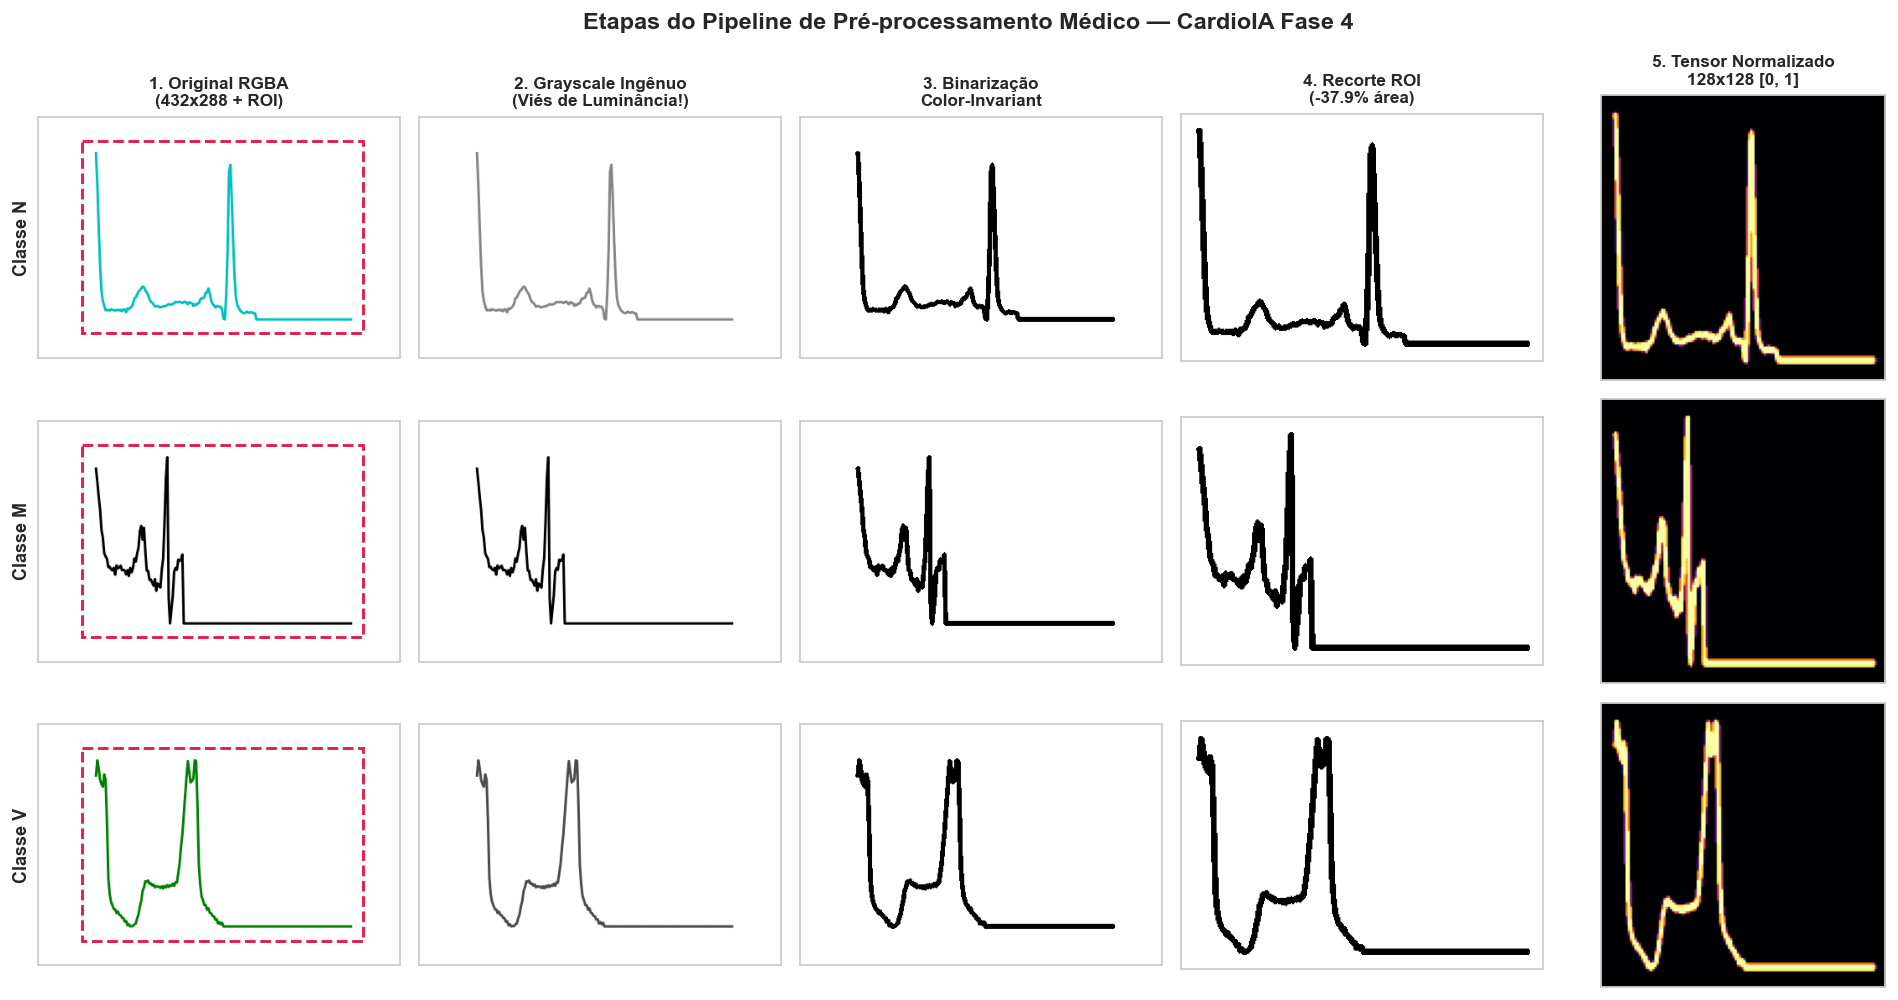

In [4]:
# Demonstração passo a passo do pipeline em 3 classes críticas (N, M, V)
fig, axes = plt.subplots(3, 5, figsize=(15, 7.8))
col_titles = [
    "1. Original RGBA\n(432x288 + ROI)",
    "2. Grayscale Ingênuo\n(Viés de Luminância!)",
    "3. Binarização\nColor-Invariant",
    f"4. Recorte ROI\n(-{summary['roi_area_reduction_pct']}% área)",
    "5. Tensor Normalizado\n128x128 [0, 1]",
]
for r, cls in enumerate(["N", "M", "V"]):
    fpath = df_manifest[(df_manifest["label"] == cls) & (df_manifest["split"] == "train")].iloc[0]["abs_path"]
    raw = Image.open(fpath)
    rgb = compor_sobre_branco(raw)
    gray = rgb.convert("L")
    mask = extrair_mascara_traco_invariante_cor(raw)
    roi = recortar_roi_ecg(mask, raw.size)
    tensor_vis = preprocessar_imagem_ecg(raw, target_size=(128, 128), modo="binarizado", para_transfer_learning=False)

    axes[r, 0].imshow(rgb)
    l, t, rx, b = STD_ROI_BOX
    axes[r, 0].add_patch(plt.Rectangle((l, t), rx - l, b - t, fill=False, edgecolor="#e11d48", lw=1.6, ls="--"))
    axes[r, 0].set_ylabel(f"Classe {cls}", fontsize=10, fontweight="bold")
    axes[r, 1].imshow(gray, cmap="gray", vmin=0, vmax=255)
    axes[r, 2].imshow(1.0 - mask, cmap="gray", vmin=0, vmax=1)
    axes[r, 3].imshow(1.0 - roi, cmap="gray", vmin=0, vmax=1)
    axes[r, 4].imshow(tensor_vis[:, :, 0], cmap="inferno", vmin=0, vmax=1)
    for c in range(5):
        if r == 0:
            axes[r, c].set_title(col_titles[c], fontsize=9.5, fontweight="bold")
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])

plt.suptitle("Etapas do Pipeline de Pré-processamento Médico — CardioIA Fase 4", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
            

---
## 4. Divisão Estratificada (Treino, Validação e Teste) e Data Augmentation Clínico

* **Treino (`240` imagens — `40/classe`, `57,1%`):** 80% da pasta `train/` original.
* **Validação (`60` imagens — `10/classe`, `14,3%`):** 20% estratificado da pasta `train/` para seleção de hiperparâmetros e melhor checkpoint.
* **Teste Independente (`120` imagens — `20/classe`, `28,6%`):** pasta `test/` original mantida 100% isolada.

No treinamento, aplicamos **Data Augmentation clinicamente válido** (pequenos deslocamentos horizontais/verticais, leve variação de ganho/espessura e ruído gaussiano sutil de eletrodo), **evitando deliberadamente flips horizontais e verticais**, pois inverter um ECG alteraria a polaridade do segmento ST (confundindo supra com infra de ST) e a sequência fisiológica P-QRS-T.
            

Distribuição Estratificada (Split x Classe):
label   F   M   N   Q   S   V  Total
split                               
train  40  40  40  40  40  40    240
val    10  10  10  10  10  10     60
test   20  20  20  20  20  20    120


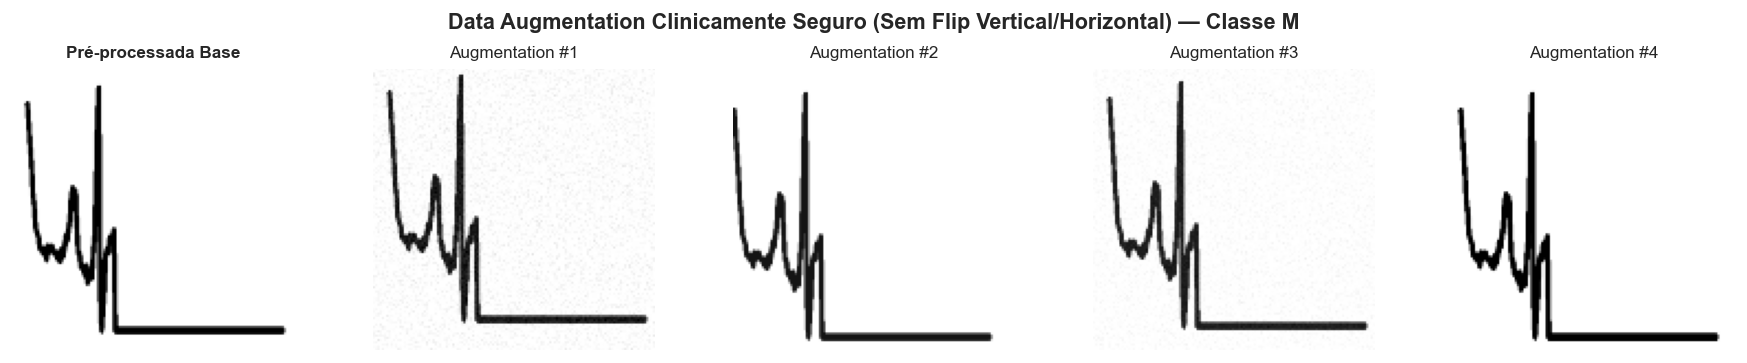

In [5]:
# Tabela de contingência Split x Classe
ct = pd.crosstab(df_manifest["split"], df_manifest["label"]).loc[["train", "val", "test"], CLASSES]
ct["Total"] = ct.sum(axis=1)
print("Distribuição Estratificada (Split x Classe):")
print(ct.to_string())

# Visualização de Data Augmentation clinicamente seguro em uma amostra de Infarto (M)
sample_m = df_manifest[(df_manifest["label"] == "M") & (df_manifest["split"] == "train")].iloc[0]["abs_path"]
base_arr = preprocessar_imagem_ecg(sample_m, target_size=(128, 128), modo="binarizado", para_transfer_learning=False)

fig, axes = plt.subplots(1, 5, figsize=(14, 2.8))
axes[0].imshow(base_arr[:, :, 0], cmap="gray_r", vmin=0, vmax=1)
axes[0].set_title("Pré-processada Base", fontsize=9.5, fontweight="bold")
axes[0].axis("off")

rng = np.random.default_rng(123)
for i in range(1, 5):
    aug = augmentar_ecg_clinico(base_arr, para_transfer=False, rng=rng)
    axes[i].imshow(aug[:, :, 0], cmap="gray_r", vmin=0, vmax=1)
    axes[i].set_title(f"Augmentation #{i}", fontsize=9.5)
    axes[i].axis("off")

plt.suptitle("Data Augmentation Clinicamente Seguro (Sem Flip Vertical/Horizontal) — Classe M", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()
            

In [6]:
# Verificação estatística dos tensores finais (média, desvio padrão e faixa de valores)
sample_paths = df_manifest[df_manifest["split"] == "train"]["abs_path"].tolist()[:30]
batch_cnn = np.stack([preprocessar_imagem_ecg(p, (128, 128), "binarizado", False) for p in sample_paths])
batch_tl = np.stack([preprocessar_imagem_ecg(p, (224, 224), "binarizado", True) for p in sample_paths])

print(f"Lote CardioCNN (Zero):      shape={batch_cnn.shape}, dtype={batch_cnn.dtype}, min={batch_cnn.min():.3f}, max={batch_cnn.max():.3f}, mean={batch_cnn.mean():.4f}")
print(f"Lote ResNet18 (Transfer):   shape={batch_tl.shape}, dtype={batch_tl.dtype}, min={batch_tl.min():.3f}, max={batch_tl.max():.3f}, mean={batch_tl.mean():.4f}")
print("Manifesto salvo em:", processed_dir / "manifest_dataset.csv")
print("Pipeline da Parte 1 validado com sucesso!")
            

Lote CardioCNN (Zero):      shape=(30, 128, 128, 1), dtype=float32, min=0.000, max=1.000, mean=0.0632
Lote ResNet18 (Transfer):   shape=(30, 224, 224, 3), dtype=float32, min=0.000, max=1.000, mean=0.9390
Manifesto salvo em: C:\Users\Pichau\Downloads\FIAP\2ANO\TRABALHOS\CardioIA\Fase4\data\processed\manifest_dataset.csv
Pipeline da Parte 1 validado com sucesso!
